In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("../data/processed/delhi_pollution_weather_daily_2020_2025.csv",
parse_dates=["Date"]).sort_values("Date")
SEASONS = ["Winter", "Summer", "Monsoon", "Post-Monsoon"]

In [2]:
print(df.shape)
print(df.describe().T)
print(df.isna().sum())
miss = df.assign(miss=df["PM2.5"].isna()).groupby(["year", "month"])["miss"].sum()
print(miss[miss > 0])


(2192, 27)
                        count                 mean                  min  \
Date                     2192  2022-12-31 12:00:00  2020-01-01 00:00:00   
PM2.5                  2130.0           107.984899                10.02   
PM10                   1985.0           167.658572                11.48   
NO2                    2139.0            56.107301                2.297   
SO2                    2164.0            14.015843                 1.12   
weather_hours          2192.0                 24.0                 24.0   
temperature_mean       2192.0            24.474181             8.020833   
temperature_min        2192.0             19.30187                  2.1   
temperature_max        2192.0            30.426414                 14.1   
humidity_mean          2192.0            63.692708               10.625   
dew_point_mean         2192.0            15.564703              -2.8125   
feels_like_mean        2192.0            25.762992             5.679167   
rain_sum      

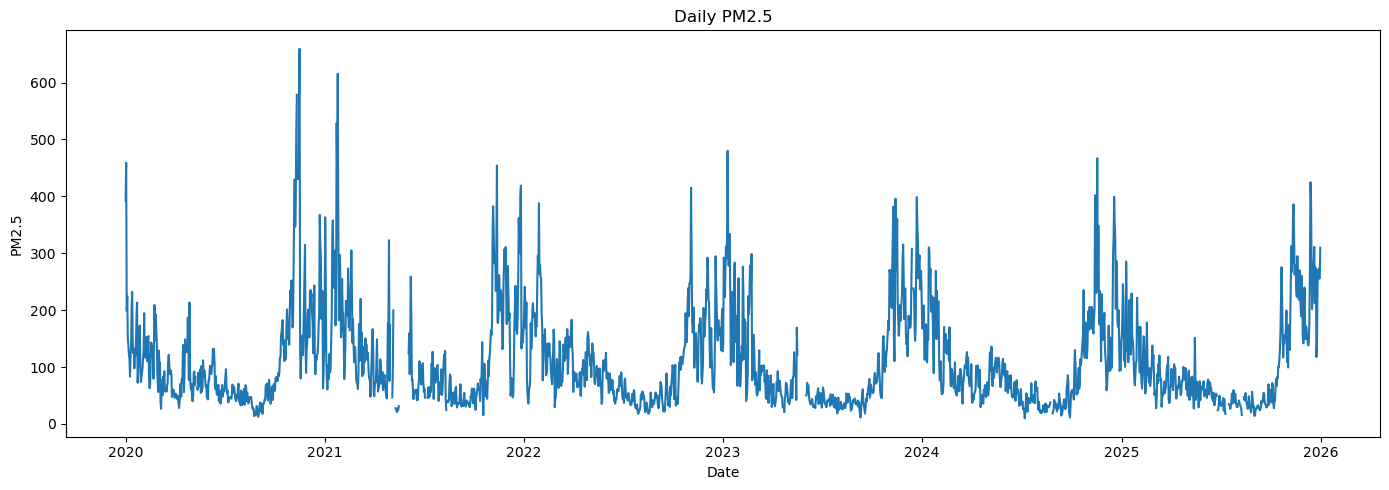

In [3]:
plt.figure(figsize=(14, 5))
plt.plot(df["Date"], df["PM2.5"])
plt.xlabel("Date"); plt.ylabel("PM2.5"); plt.title("Daily PM2.5")
plt.tight_layout(); plt.show()

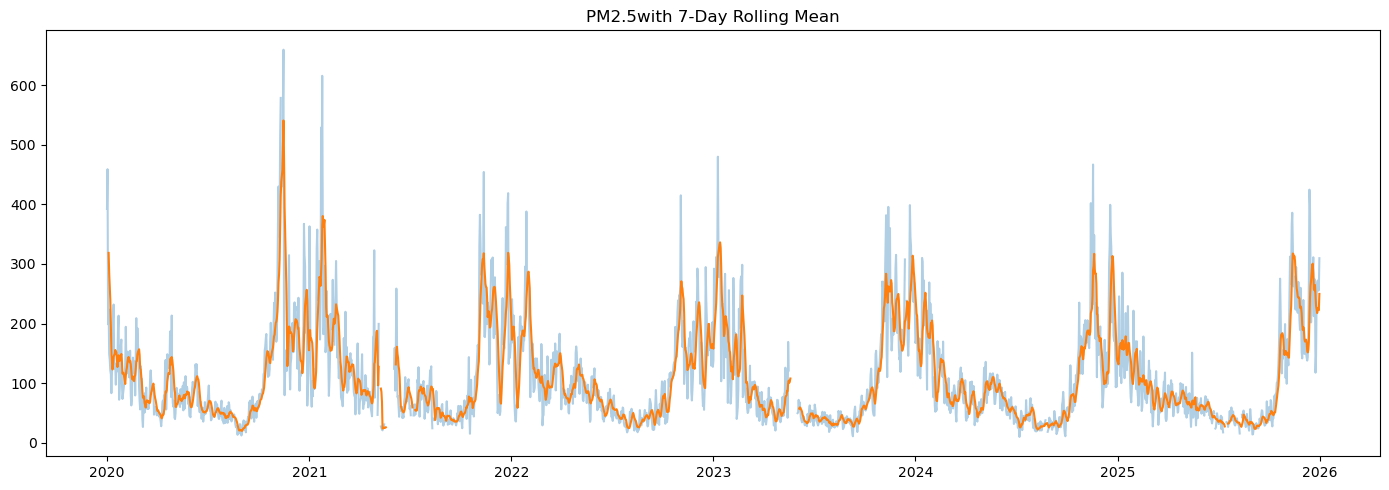

In [4]:
df["pm25_roll7_eda"] = df["PM2.5"].rolling(7,min_periods=4).mean()
plt.figure(figsize=(14, 5))
plt.plot(df["Date"], df["PM2.5"], alpha=0.35)
plt.plot(df["Date"], df["pm25_roll7_eda"])
plt.title("PM2.5with 7-Day Rolling Mean")
plt.tight_layout();plt.show()

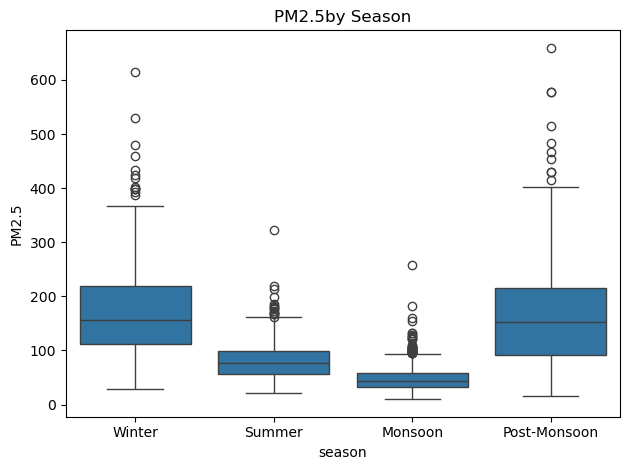

H = 1204.0167253766567  p = 9.8561340751747e-261
epsilon^2(effect size) = 0.5655315760341272


In [7]:
sns.boxplot(data=df, x="season", y="PM2.5",order=SEASONS)
plt.title("PM2.5by Season"); plt.tight_layout(); plt.show()
from scipy.stats import kruskal
groups = [df.loc[df["season"] == s, "PM2.5"].dropna().values for s in SEASONS]
H, p = kruskal(*groups)
n = sum(len(g) for g in groups)
print("H =", H, " p =", p)
print("epsilon^2(effect size) =", H/ (n- 1))

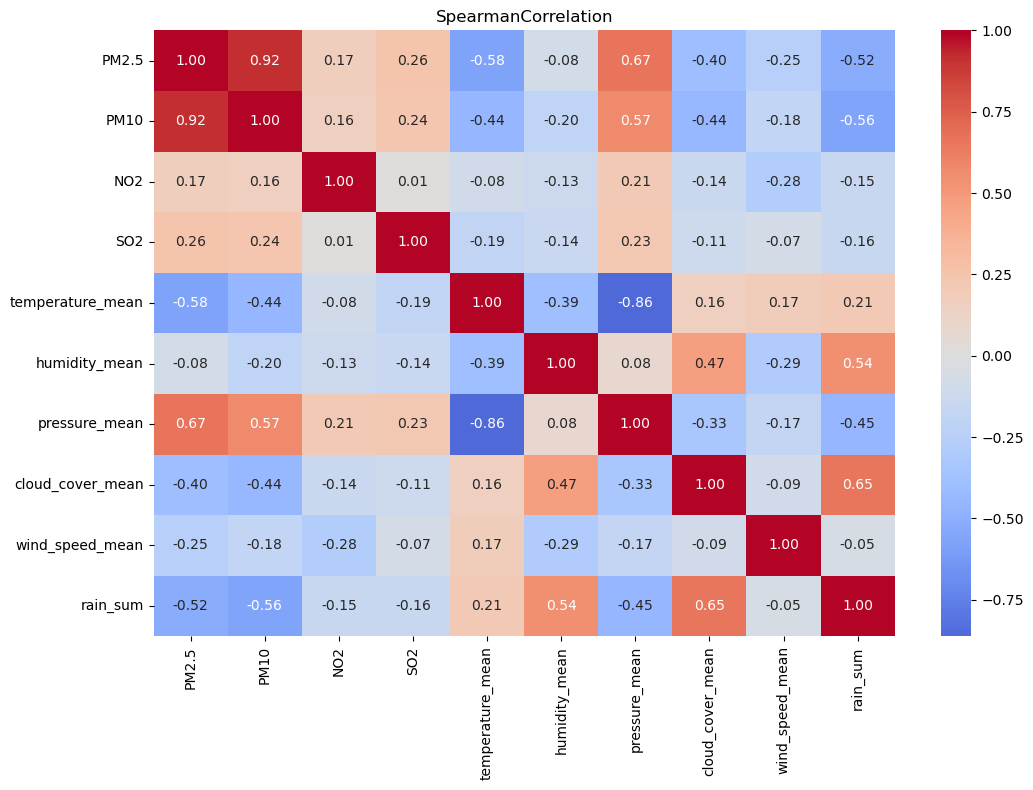

In [8]:
cols = ["PM2.5", "PM10", "NO2", "SO2", "temperature_mean", "humidity_mean",
"pressure_mean","cloud_cover_mean", "wind_speed_mean", "rain_sum"]
corr = df[cols].corr(method="spearman") # pairwisedeletion of NaN
plt.figure(figsize=(11, 8))
sns.heatmap(corr,annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("SpearmanCorrelation"); plt.tight_layout(); plt.show()

In [10]:
for season in SEASONS:
    g = df[df["season"] == season]
    tmp = g[["PM2.5", "wind_speed_mean", "temperature_mean",
    "humidity_mean","pressure_mean"]].dropna()
    print("\n---",season, "---")
    print(tmp.corr(method="spearman")["PM2.5"])


--- Winter ---
PM2.5               1.000000
wind_speed_mean    -0.412004
temperature_mean   -0.221703
humidity_mean       0.328279
pressure_mean       0.052341
Name: PM2.5, dtype: float64

--- Summer ---
PM2.5               1.000000
wind_speed_mean    -0.141608
temperature_mean    0.161564
humidity_mean      -0.125601
pressure_mean      -0.049227
Name: PM2.5, dtype: float64

--- Monsoon ---
PM2.5               1.000000
wind_speed_mean    -0.127490
temperature_mean    0.441124
humidity_mean      -0.395366
pressure_mean      -0.168853
Name: PM2.5, dtype: float64

--- Post-Monsoon ---
PM2.5               1.000000
wind_speed_mean    -0.281948
temperature_mean   -0.558912
humidity_mean      -0.179481
pressure_mean       0.590094
Name: PM2.5, dtype: float64


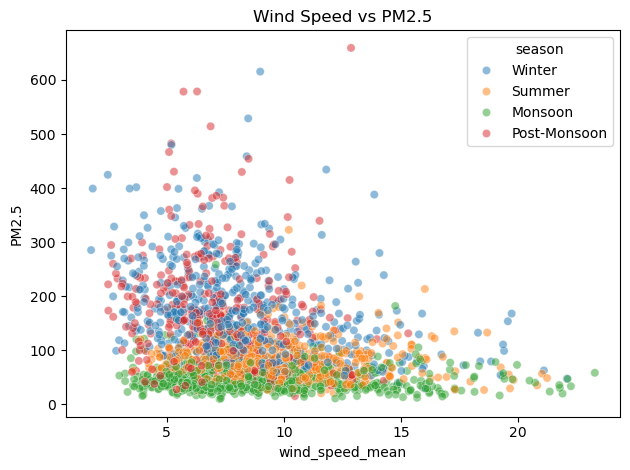

In [11]:
sns.scatterplot(data=df, x="wind_speed_mean", y="PM2.5",
hue="season", hue_order=SEASONS, alpha=0.5)
plt.title("Wind Speed vs PM2.5"); plt.tight_layout(); plt.show()